# BÁO CÁO PHẦN 1 - BÀI 2 (TRANG 28): BANK MARKETING DATASET
## CÂU 4: Khảo sát các biến tài chính và tương tác chiến dịch với quyết định gửi tiền (y)
- Khảo sát các biến: Thời lượng cuộc gọi (`duration`), Khoản vay nhà (`housing`), Khoản vay cá nhân (`loan`), Kết quả chiến dịch trước (`poutcome`)
- Vẽ biểu đồ và đưa ra nhận xét


Họ tên: Hoàng Thành Đạt - MSSV: 6451071016


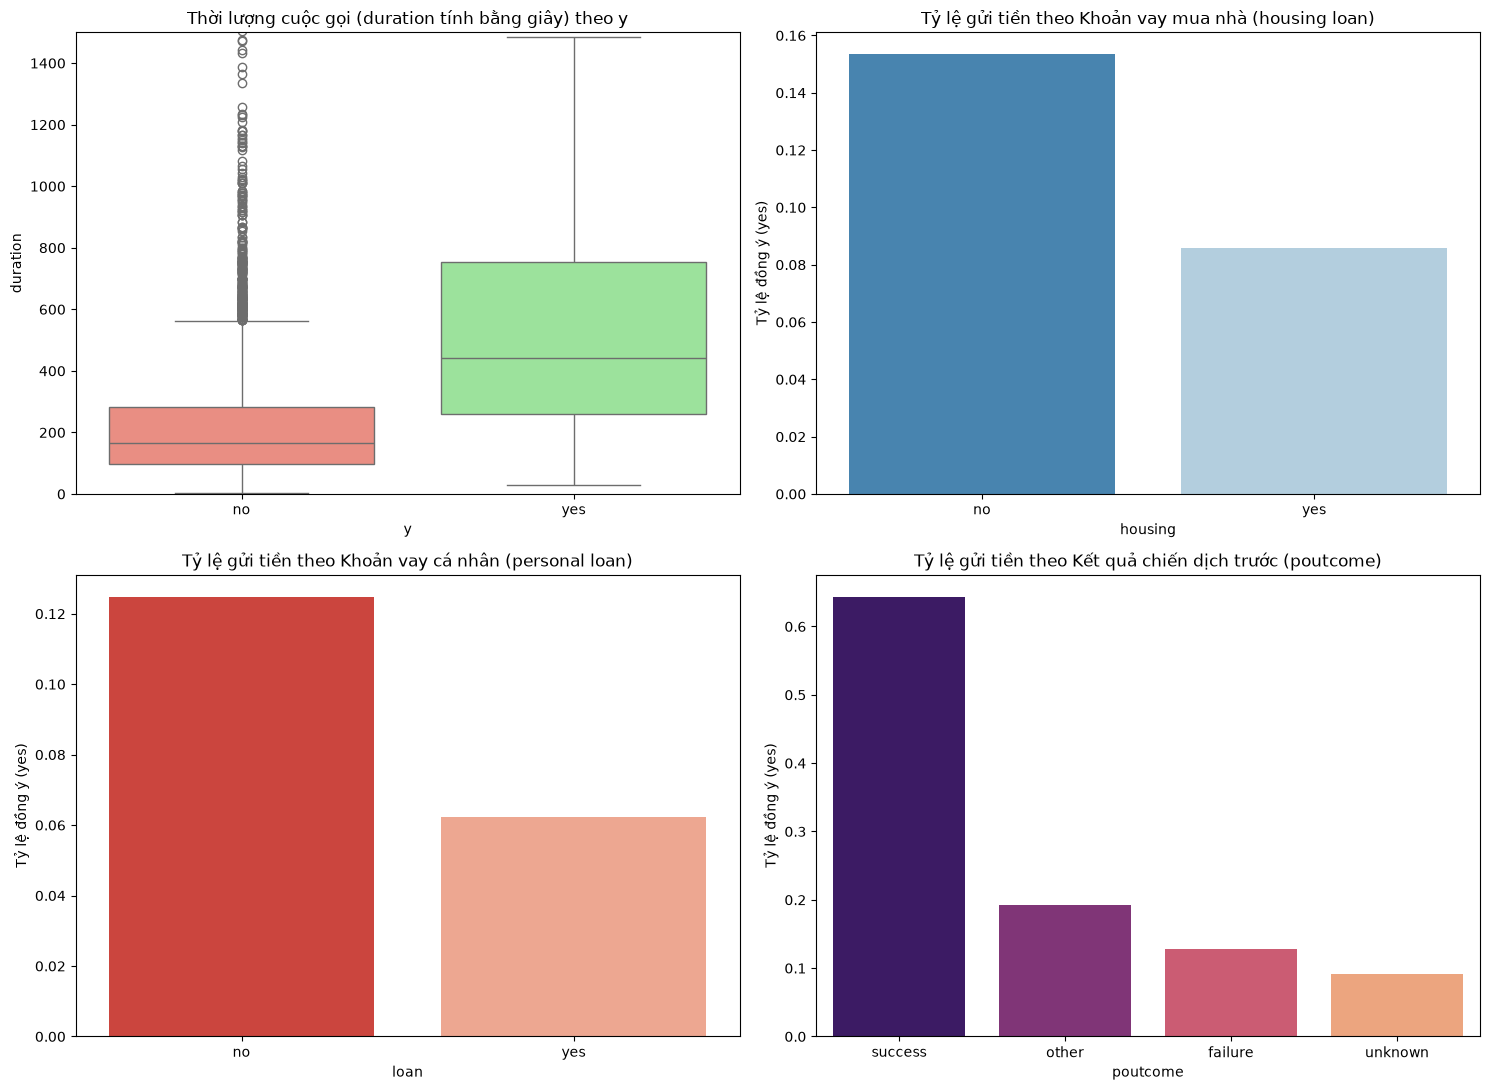

In [1]:
# ==========================================
# THÔNG TIN SINH VIÊN THỰC HIỆN
# Họ và tên: Hoàng Thành Đạt
# MSSV: 6451071016
# ==========================================
ho_ten = "Hoàng Thành Đạt"
mssv = "6451071016"
print(f"Họ tên: {ho_ten} - MSSV: {mssv}")

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def get_data_path(rel_filename):
    for candidate in [
        os.path.join("..", "..", "dataset", rel_filename),
        os.path.join("..", "dataset", rel_filename),
        os.path.join("dataset", rel_filename),
        rel_filename
    ]:
        if os.path.exists(candidate):
            return candidate
    return rel_filename


path = get_data_path(os.path.join('bank', 'bank.csv'))
if not os.path.exists(path):
    path = get_data_path('bank.csv')

df = pd.read_csv(path, sep=';')
df['target'] = (df['y'] == 'yes').astype(int)

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Thời lượng cuộc gọi (duration) theo quyết định y
sns.boxplot(data=df, x='y', y='duration', ax=axes[0, 0], palette=['salmon', 'lightgreen'])
axes[0, 0].set_title("Thời lượng cuộc gọi (duration tính bằng giây) theo y")
axes[0, 0].set_ylim(0, 1500)

# 2. Vay nợ mua nhà (housing) ảnh hưởng đến quyết định
housing_rate = df.groupby('housing')['target'].mean().reset_index()
sns.barplot(data=housing_rate, x='housing', y='target', ax=axes[0, 1], palette='Blues_r')
axes[0, 1].set_title("Tỷ lệ gửi tiền theo Khoản vay mua nhà (housing loan)")
axes[0, 1].set_ylabel("Tỷ lệ đồng ý (yes)")

# 3. Vay nợ cá nhân (loan) ảnh hưởng đến quyết định
loan_rate = df.groupby('loan')['target'].mean().reset_index()
sns.barplot(data=loan_rate, x='loan', y='target', ax=axes[1, 0], palette='Reds_r')
axes[1, 0].set_title("Tỷ lệ gửi tiền theo Khoản vay cá nhân (personal loan)")
axes[1, 0].set_ylabel("Tỷ lệ đồng ý (yes)")

# 4. Kết quả chiến dịch trước (poutcome)
poutcome_rate = df.groupby('poutcome')['target'].mean().sort_values(ascending=False).reset_index()
sns.barplot(data=poutcome_rate, x='poutcome', y='target', ax=axes[1, 1], palette='magma')
axes[1, 1].set_title("Tỷ lệ gửi tiền theo Kết quả chiến dịch trước (poutcome)")
axes[1, 1].set_ylabel("Tỷ lệ đồng ý (yes)")

plt.tight_layout()
plt.show()


### Nhận xét Câu 4:
- **Thời lượng cuộc gọi (`duration`)**: Đây là đặc trưng có tính phân loại mạnh nhất. Khách hàng đồng ý (`yes`) có thời lượng cuộc gọi trung bình lớn hơn rất nhiều (thường > 500 giây) so với người từ chối.
- **Nợ vay (`housing`, `loan`)**: Khách hàng không có nợ nhà (`housing = no`) và không có nợ cá nhân (`loan = no`) có tỷ lệ gửi tiết kiệm cao gấp đôi so với nhóm đang có nợ.
- **Kết quả chiến dịch trước (`poutcome`)**: Khách hàng từng có kết quả thành công trong quá khứ (`success`) có tỷ lệ đồng ý gửi tiền vượt trội (> 60%), đây là nhóm khách hàng tiềm năng lớn nhất cần ưu tiên liên hệ.
